ADALINE OR GATE RESULTS
-------------------------------------------------------
Final weights: [0.47058824 0.44117647]
Final bias: 0.5000000000000001
Final training MSE: 0.254325

Input 1 | Input 2 | Linear Output | Prediction | Target
-------------------------------------------------------------
     -1 |      -1 |       -0.4118 |         -1 |     -1
     -1 |       1 |        0.4706 |          1 |      1
      1 |      -1 |        0.5294 |          1 |      1
      1 |       1 |        1.4118 |          1 |      1

Classification accuracy: 100.00%


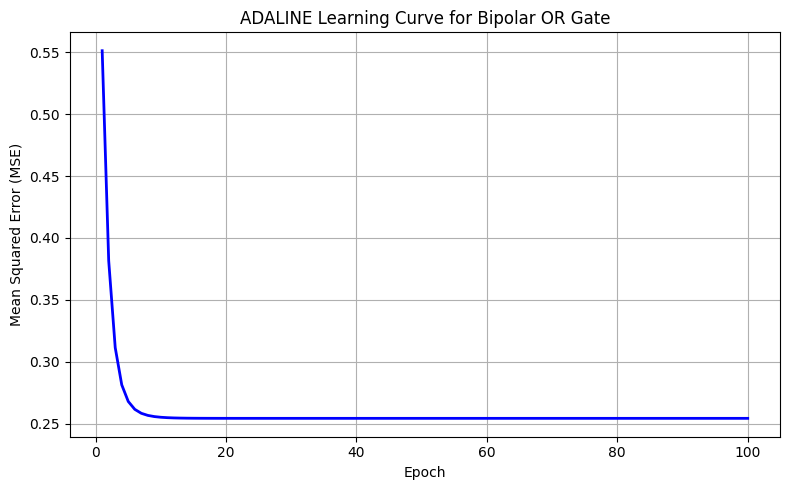

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# GRADED TASK 1: ADALINE FOR BIPOLAR OR GATE
# ==========================================

# 1. Bipolar OR truth table
X = np.array([
    [-1, -1],
    [-1,  1],
    [ 1, -1],
    [ 1,  1]
], dtype=float)

y = np.array([-1, 1, 1, 1], dtype=float)

# 2. Reproducible initialization
rng = np.random.default_rng(7)
w = rng.normal(0, 0.1, size=2)
b = 0.0

learning_rate = 0.1
epochs = 100
loss_history = []

# 3. Train ADALINE using the online delta rule
for epoch in range(epochs):
    for xi, target in zip(X, y):
        # Linear net input
        output = np.dot(xi, w) + b

        # Continuous error
        error = target - output

        # Delta-rule updates
        w += learning_rate * error * xi
        b += learning_rate * error

    # Calculate MSE after completing each epoch
    outputs = X @ w + b
    mse = np.mean((y - outputs) ** 2)
    loss_history.append(mse)

# 4. Display learned parameters
print("ADALINE OR GATE RESULTS")
print("-" * 55)
print("Final weights:", w)
print("Final bias:", b)
print(f"Final training MSE: {loss_history[-1]:.6f}")

# 5. Predictions for all input combinations
outputs = X @ w + b
predictions = np.where(outputs >= 0, 1, -1)

print("\nInput 1 | Input 2 | Linear Output | Prediction | Target")
print("-" * 61)

for xi, output, pred, target in zip(
    X, outputs, predictions, y
):
    print(
        f"{int(xi[0]):7d} | {int(xi[1]):7d} | "
        f"{output:13.4f} | {pred:10d} | {int(target):6d}"
    )

accuracy = np.mean(predictions == y) * 100
print(f"\nClassification accuracy: {accuracy:.2f}%")

# 6. Plot learning curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), loss_history,
         color="blue", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("ADALINE Learning Curve for Bipolar OR Gate")
plt.grid(True)
plt.tight_layout()
plt.show()


Dataset sizes
Training: 90
Validation: 30
Testing: 30


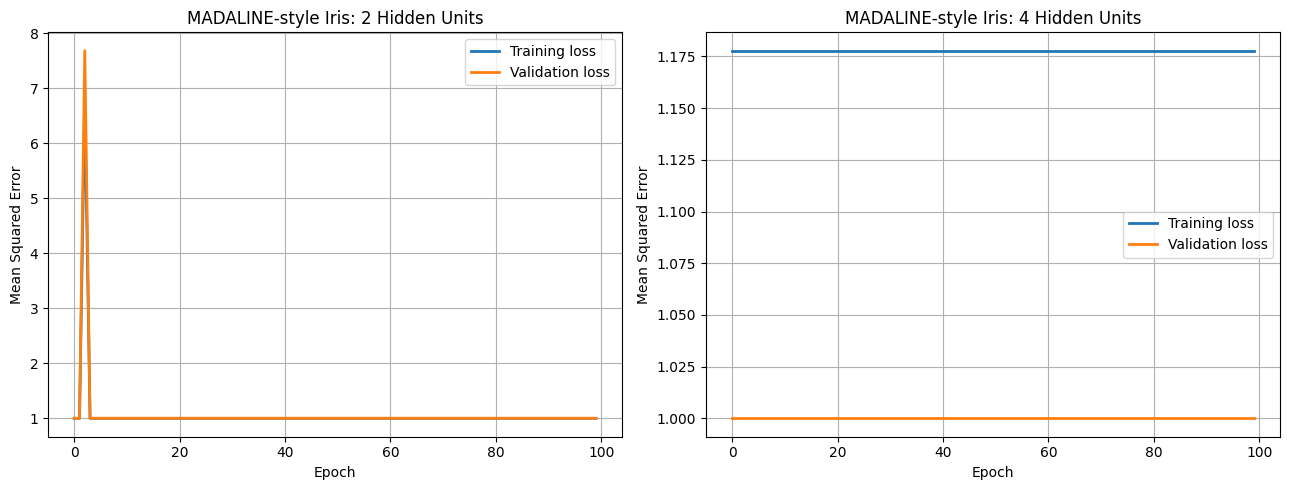


MODEL WITH 2 HIDDEN UNITS
Training accuracy: 1.0000
Validation accuracy: 1.0000
Test accuracy: 1.0000

Validation confusion matrix:
Rows = actual; columns = predicted
Order: ['Setosa (-1)', 'Other (+1)']
[[10  0]
 [ 0 20]]


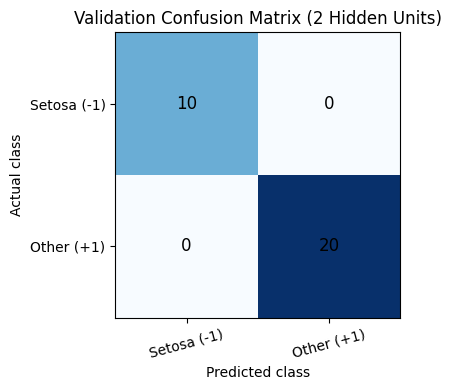


Test confusion matrix:
Rows = actual; columns = predicted
Order: ['Setosa (-1)', 'Other (+1)']
[[10  0]
 [ 0 20]]


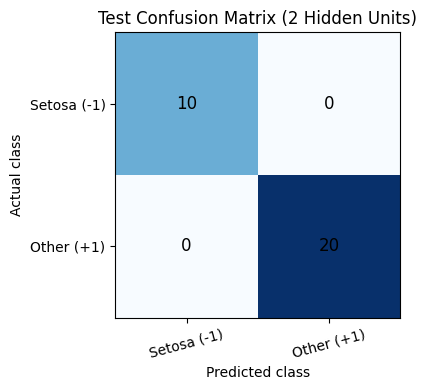


MODEL WITH 4 HIDDEN UNITS
Training accuracy: 1.0000
Validation accuracy: 1.0000
Test accuracy: 1.0000

Validation confusion matrix:
Rows = actual; columns = predicted
Order: ['Setosa (-1)', 'Other (+1)']
[[10  0]
 [ 0 20]]


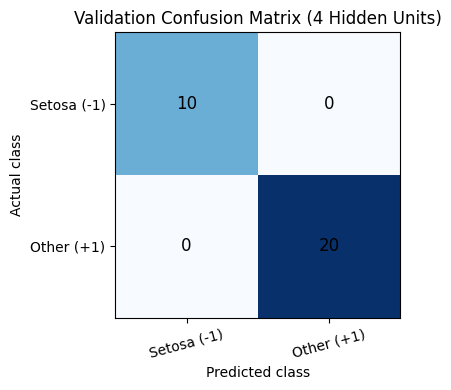


Test confusion matrix:
Rows = actual; columns = predicted
Order: ['Setosa (-1)', 'Other (+1)']
[[10  0]
 [ 0 20]]


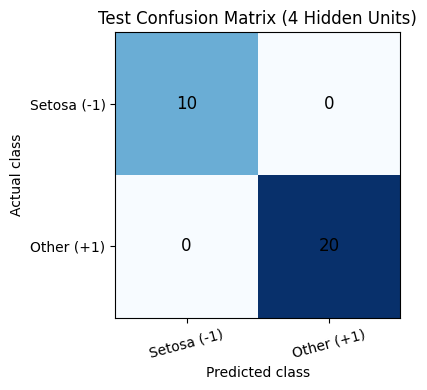


SUMMARY: HIDDEN-UNIT COMPARISON
-----------------------------------------------------------------
Hidden units   Train acc.     Val. acc.      Test acc.      
2              1.0000         1.0000         1.0000         
4              1.0000         1.0000         1.0000         


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score

# =====================================================
# GRADED TASK 2: MADALINE-STYLE BINARY IRIS CLASSIFIER
# =====================================================

# 1. Load dataset and encode binary targets
iris = load_iris()
X = iris.data.astype(float)

# Setosa = -1; versicolor and virginica = +1
y = np.where(iris.target == 0, -1.0, 1.0)

# 2. Stratified 60% / 20% / 20% split
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# 3. Fit scaler ONLY on training data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Dataset sizes")
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))


class SimpleMadaline:
    """
    Educational MRII-inspired binary classifier.

    Hidden units use bipolar sign activations.
    When a sample is misclassified, the hidden unit
    closest to the decision boundary is adjusted.
    This is a heuristic MRII-inspired rule, not a
    canonical implementation of historical MRII.
    """

    def __init__(
        self, n_features, n_hidden=2,
        lr=0.02, seed=12
    ):
        rng = np.random.default_rng(seed)

        self.W = rng.normal(
            0, 0.15, size=(n_features, n_hidden)
        )
        self.bh = np.zeros(n_hidden)

        # Hidden-to-output combination
        self.v = np.ones(n_hidden)
        self.bo = 0.0
        self.lr = lr

    def forward(self, X):
        hidden_net = X @ self.W + self.bh

        # Bipolar sign activation
        hidden = np.where(
            hidden_net >= 0, 1.0, -1.0
        )

        # Continuous score for loss monitoring
        score = hidden @ self.v + self.bo

        return hidden_net, hidden, score

    def predict(self, X):
        _, _, score = self.forward(X)
        return np.where(score >= 0, 1.0, -1.0)

    def fit(
        self, X, y, X_val, y_val, epochs=100
    ):
        train_losses = []
        val_losses = []

        for epoch in range(epochs):

            # Online sample-by-sample updates
            for xi, target in zip(X, y):

                nets, hidden, score = self.forward(
                    xi.reshape(1, -1)
                )

                nets = nets[0]
                score = float(score[0])
                pred = 1.0 if score >= 0 else -1.0

                if pred != target:

                    # Select hidden unit closest to zero
                    j = int(np.argmin(np.abs(nets)))

                    # Target-dependent hidden margin
                    desired = 0.5 * target
                    error = desired - nets[j]

                    # Update selected hidden ADALINE
                    self.W[:, j] += (
                        self.lr * error * xi
                    )
                    self.bh[j] += self.lr * error

                    # Adjust output combination
                    self.v[j] = target
                    self.bo += (
                        self.lr * (target - score) * 0.1
                    )

            # Continuous-score MSE
            train_score = self.forward(X)[2]
            val_score = self.forward(X_val)[2]

            train_losses.append(
                np.mean((y - train_score) ** 2)
            )
            val_losses.append(
                np.mean((y_val - val_score) ** 2)
            )

        return train_losses, val_losses


# 4. Train two different hidden-unit configurations
hidden_settings = [2, 4]
results = {}

for n_hidden in hidden_settings:

    model = SimpleMadaline(
        n_features=X_train.shape[1],
        n_hidden=n_hidden,
        lr=0.02,
        seed=12
    )

    train_loss, val_loss = model.fit(
        X_train, y_train,
        X_val, y_val,
        epochs=100
    )

    results[n_hidden] = {
        "model": model,
        "train_loss": train_loss,
        "val_loss": val_loss
    }


# 5. Plot training and validation loss for both models
fig, axes = plt.subplots(
    1, 2, figsize=(13, 5), sharey=False
)

for ax, n_hidden in zip(axes, hidden_settings):

    result = results[n_hidden]

    ax.plot(
        result["train_loss"],
        label="Training loss",
        linewidth=2
    )
    ax.plot(
        result["val_loss"],
        label="Validation loss",
        linewidth=2
    )

    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean Squared Error")
    ax.set_title(
        f"MADALINE-style Iris: {n_hidden} Hidden Units"
    )
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()


# 6. Evaluate both models
labels = [-1.0, 1.0]
class_names = ["Setosa (-1)", "Other (+1)"]

for n_hidden in hidden_settings:

    model = results[n_hidden]["model"]

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)
    test_pred = model.predict(X_test)

    print("\n" + "=" * 60)
    print(f"MODEL WITH {n_hidden} HIDDEN UNITS")
    print("=" * 60)

    print(
        f"Training accuracy: "
        f"{accuracy_score(y_train, train_pred):.4f}"
    )
    print(
        f"Validation accuracy: "
        f"{accuracy_score(y_val, val_pred):.4f}"
    )
    print(
        f"Test accuracy: "
        f"{accuracy_score(y_test, test_pred):.4f}"
    )

    # Confusion matrices
    for name, true_y, pred_y in [
        ("Validation", y_val, val_pred),
        ("Test", y_test, test_pred)
    ]:

        cm = confusion_matrix(
            true_y, pred_y, labels=labels
        )

        print(f"\n{name} confusion matrix:")
        print("Rows = actual; columns = predicted")
        print("Order:", class_names)
        print(cm)

        # Plot confusion matrix
        fig, ax = plt.subplots(figsize=(5, 4))
        ax.imshow(cm, cmap="Blues")

        ax.set_title(
            f"{name} Confusion Matrix "
            f"({n_hidden} Hidden Units)"
        )
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("Actual class")

        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])
        ax.set_xticklabels(class_names, rotation=15)
        ax.set_yticklabels(class_names)

        # Write cell counts
        for i in range(2):
            for j in range(2):
                ax.text(
                    j, i, str(cm[i, j]),
                    ha="center", va="center",
                    color="black", fontsize=12
                )

        plt.tight_layout()
        plt.show()


# 7. Summary comparison
print("\nSUMMARY: HIDDEN-UNIT COMPARISON")
print("-" * 65)
print(
    f"{'Hidden units':<15}"
    f"{'Train acc.':<15}"
    f"{'Val. acc.':<15}"
    f"{'Test acc.':<15}"
)

for n_hidden in hidden_settings:

    model = results[n_hidden]["model"]

    train_acc = accuracy_score(
        y_train, model.predict(X_train)
    )
    val_acc = accuracy_score(
        y_val, model.predict(X_val)
    )
    test_acc = accuracy_score(
        y_test, model.predict(X_test)
    )

    print(
        f"{n_hidden:<15}"
        f"{train_acc:<15.4f}"
        f"{val_acc:<15.4f}"
        f"{test_acc:<15.4f}"
    )
